# 安全头盔和反光背心目标检测

In [ ]:
# !pip install ultralytics

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights 和 Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

In [2]:
datasets_path = 'safety-Helmet-Reflective-Jacket'

In [3]:
def count_jpg_images(datasets_path = datasets_path, subset = "train/images"):
    """
    统计指定目录中的 JPG 图片数量

    该函数给定的数据集路径和子集目录中查找以 .jpg 结尾的文件，并返回这些文件的总数。如果指定的目录不存在或不是目录，则返回 0

    参数：
    datasets_path (str): 数据集的主路径，子集目录位于此路径下
    subset (str): 图片所在的特定目录，默认为 train/images

    返回：
    int: JPG 图片的数量
    """
    # 拼接数据集路径和子集目录，获取图片所在目录的完整路径
    images_dir = os.path.join(datasets_path, subset)

    # 检查图片目录是否存在且确实是一个目录
    if os.path.exists(images_dir) and os.path.isdir(images_dir):
        # 使用列表推导式筛选出以 .jpg 结尾的文件（忽略大小写），并计算其数量
        jpg_count = len([filename for filename in os.listdir(images_dir) if filename.lower().endswith('.jpg')])
    else:
        # 如果目录不存在或不是目录，则计算结果为 0
        jpg_count = 0
        
    # 返回 JPG 图片的数量
    return jpg_count

In [4]:
print(" 训练集样本数量： ", count_jpg_images())
print(" 验证集样本数量： ", count_jpg_images(subset = 'valid/images'))
print(" 测试集样本数量： ", count_jpg_images(subset = 'test/images'))

 训练集样本数量：  7350
 验证集样本数量：  1575
 测试集样本数量：  1575


In [5]:
# 训练集图片的路径
image_directory = os.path.join(datasets_path, 'train/images')

# 获取目录中所有的 jpg 图片
jpg_files = [f for f in os.listdir(image_directory) if f.endswith('.jpg')]

# 随机选择 6 张图片
selected_images = random.sample(jpg_files, 4)

for selected_image in selected_images:
    image_path = os.path.join(image_directory, selected_image)

    # 打开图片并获取尺寸
    with Image.open(image_path) as img:
        width, height = img.size
        print(f" 选择的图片：{selected_image}")
        print(f" 图片尺寸：宽度 = {width}, 高度 = {height}")


 选择的图片：helmet_jacket_00951.jpg
 图片尺寸：宽度 = 640, 高度 = 640
 选择的图片：helmet_jacket_06374.jpg
 图片尺寸：宽度 = 640, 高度 = 640
 选择的图片：helmet_jacket_02378.jpg
 图片尺寸：宽度 = 640, 高度 = 640
 选择的图片：helmet_jacket_06489.jpg
 图片尺寸：宽度 = 640, 高度 = 640


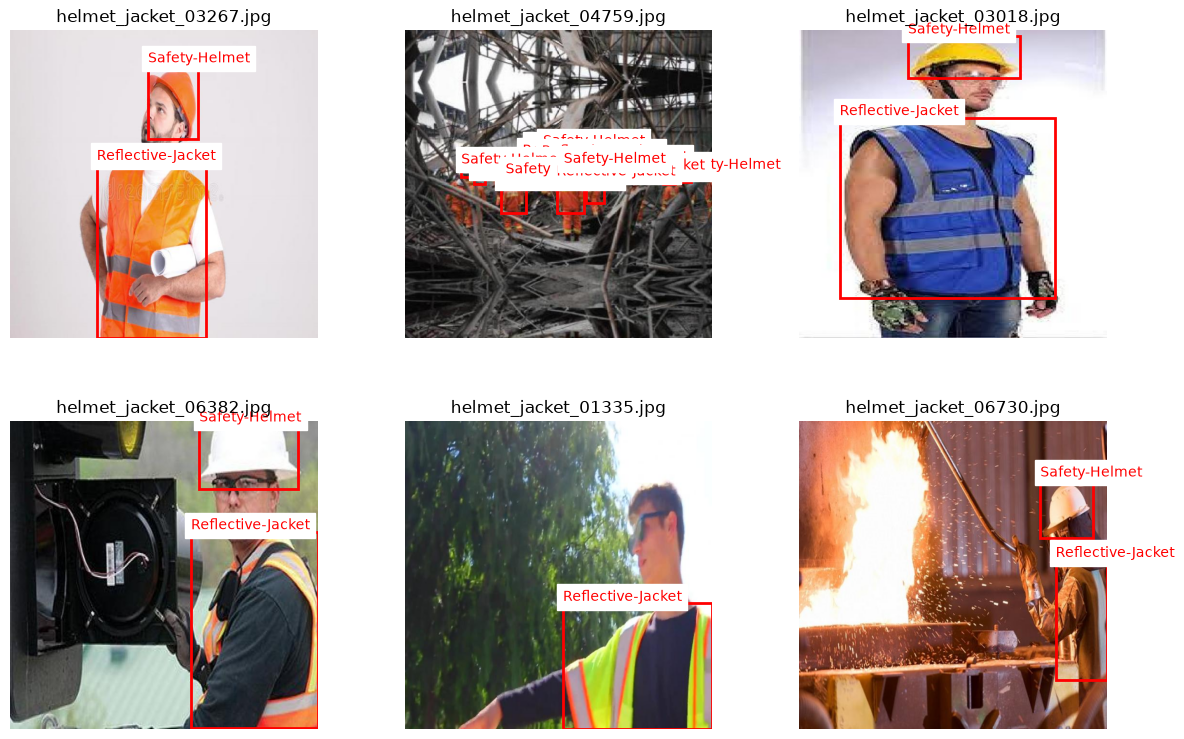

In [6]:
# 定义标签名称
label_names = {0: 'Safety-Helmet', 1: 'Reflective-Jacket'}
image_directory = os.path.join(datasets_path, 'train/images')
label_directory = os.path.join(datasets_path, 'train/labels')

# 获取目录中所有的 .jpg 文件
jpg_files = [f for f in os.listdir(image_directory) if f.endswith('.jpg')]

# 随机选择 6 张图片
selected_images = random.sample(jpg_files, 6)
# 创建一个 2 * 3 的子图布局
fig, axes = plt.subplots(2, 3, figsize = (12, 8))
# 遍历指定的图片并显示在子图中
for ax, selected_image in zip(axes.flatten(), selected_images):
    image_path = os.path.join(image_directory, selected_image)
    label_path = os.path.join(label_directory, selected_image.replace('.jpg', '.txt'))
    # 打开图片并获取尺寸
    with Image.open(image_path) as img:
        width, height = img.size
        # 显示图片
        ax.imshow(img)
        ax.set_title(selected_image)
        ax.axis('off') # 关闭坐标轴
        # 读取标签文件
        if os.path.exists(label_path):
            with open(label_path, 'r') as label_file:
                for line in label_file:
                    label_info = line.strip().split()
                    label_id = int(label_info[0])
                    x_center, y_center, bbox_width, bbox_height = map(float, label_info[1:5])
                    # 计算边界框的左上角和右下角的坐标
                    x_min = (x_center - bbox_width / 2) * width
                    y_min = (y_center - bbox_height / 2) * height
                    x_max = (x_center + bbox_width / 2) * width
                    y_max = (y_center + bbox_height / 2) * height
                    # 绘制边界框
                    rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth = 2, edgecolor = 'r', facecolor = 'none')

                    ax.add_patch(rect)
                    # 显示标签名称
                    ax.text(x_min, y_min - 5, label_names[label_id], color = 'r', fontsize = 10, backgroundcolor = 'white')
# 调整子图之间的间距
plt.tight_layout()
plt.show()